In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
import numpy as np



# Load datasets
cpi = pd.read_csv("cpi_turkey_historical.csv", sep=";")
retail = pd.read_csv("retail_sales_volume_turkey.csv", sep=";")

# Clean CPI data
cpi = cpi[cpi["DEGISIM"] == 1].copy()

cpi["date"] = pd.to_datetime(cpi["Time period (TIME_PERIOD)"])

cpi["cpi"] = pd.to_numeric(
    cpi["Observation Value"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

cpi = cpi[["date", "cpi"]]

# Clean Retail Sales data
retail = retail[
    (retail["ACTIVITY"] == "G47") &
    (retail["DEGISIM_TUR"] == 1) &
    (retail["SEASONAL_ADJUST"] == "Y")
].copy()

retail["date"] = pd.to_datetime(retail["Time period (TIME_PERIOD)"])

retail["retail_sales"] = pd.to_numeric(
    retail["Observation Value"],
    errors="coerce"
)

retail = retail[["date", "retail_sales"]]

# Merge datasets
df = pd.merge(
    cpi,
    retail,
    on="date",
    how="inner"
)

# Sort data by date
df = df.sort_values("date").reset_index(drop=True)

# Check missing values
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nMissing values:")
print(df.isnull().sum())

# Save cleaned dataset
df.to_csv(
    "turkey_cpi_retail_cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")

Dataset shape: (201, 3)

First 5 rows:
        date       cpi  retail_sales
0 2010-01-01  5.468346     52.584585
1 2010-02-01  5.547511     53.043997
2 2010-03-01  5.579868     54.023255
3 2010-04-01  5.613168     54.560324
4 2010-05-01  5.593063     55.116046

Last 5 rows:
          date     cpi  retail_sales
196 2026-05-01  128.72    202.828221
197 2026-06-01  129.99    203.036933
198 2026-07-01  132.31    202.660628
199 2026-08-01  134.75    205.905330
200 2026-09-01  137.23    206.193527

Missing values:
date            0
cpi             0
retail_sales    0
dtype: int64

Cleaned dataset saved successfully!


Descriptive Statistics:


,cpi,retail_sales
count,201.00,201.00
mean,27.65,99.56
std,34.16,41.14
min,5.47,52.58
25%,7.45,72.22
50%,10.94,82.89
75%,31.45,110.68
max,137.23,206.19



Monthly Percentage Changes:


,cpi_monthly_change,retail_monthly_change
count,200.00,200.00
mean,1.64,0.73
std,1.98,2.79
min,-1.44,-20.01
25%,0.51,-0.30
50%,1.12,0.91
75%,2.25,1.86
max,13.58,15.88


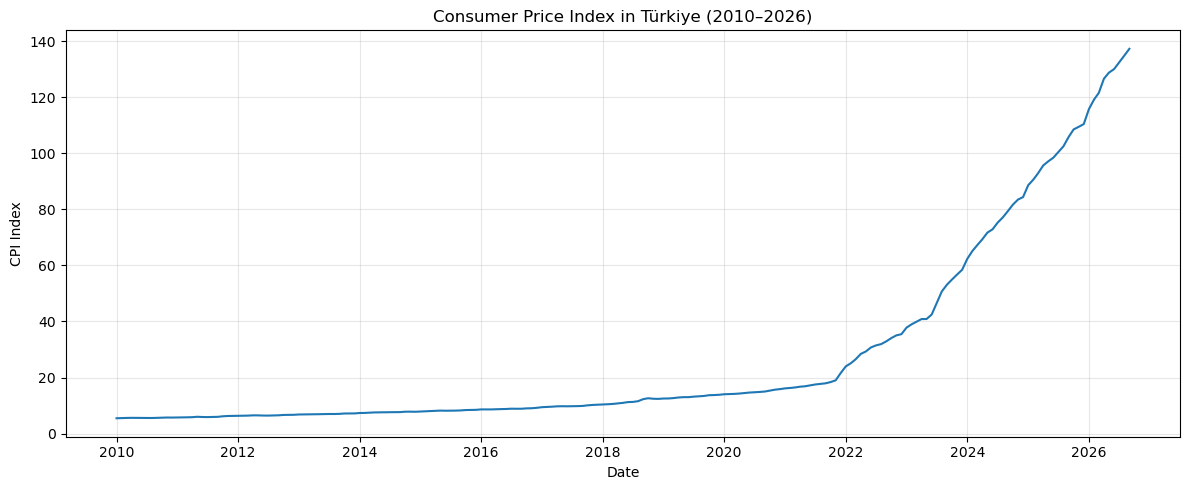

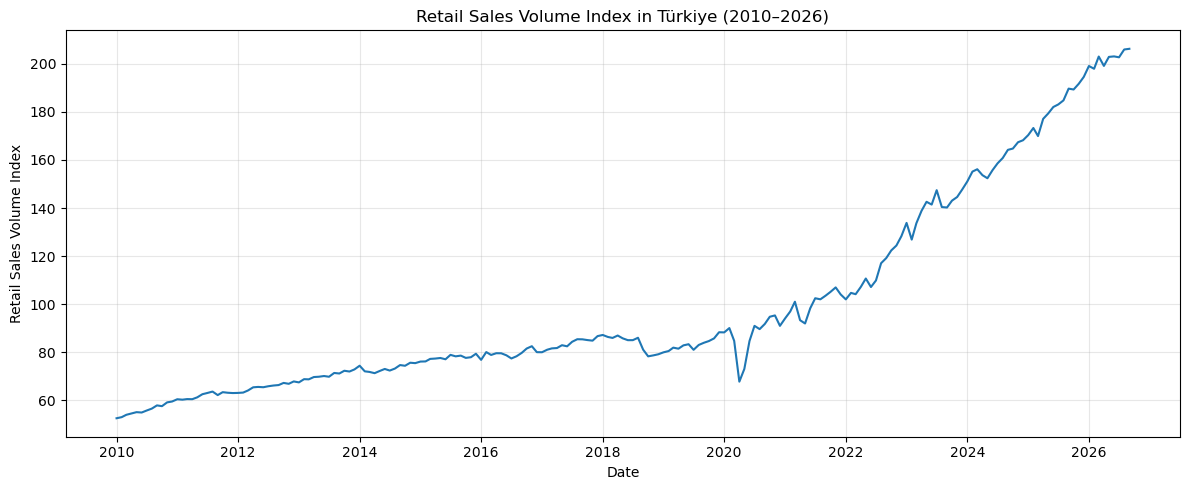

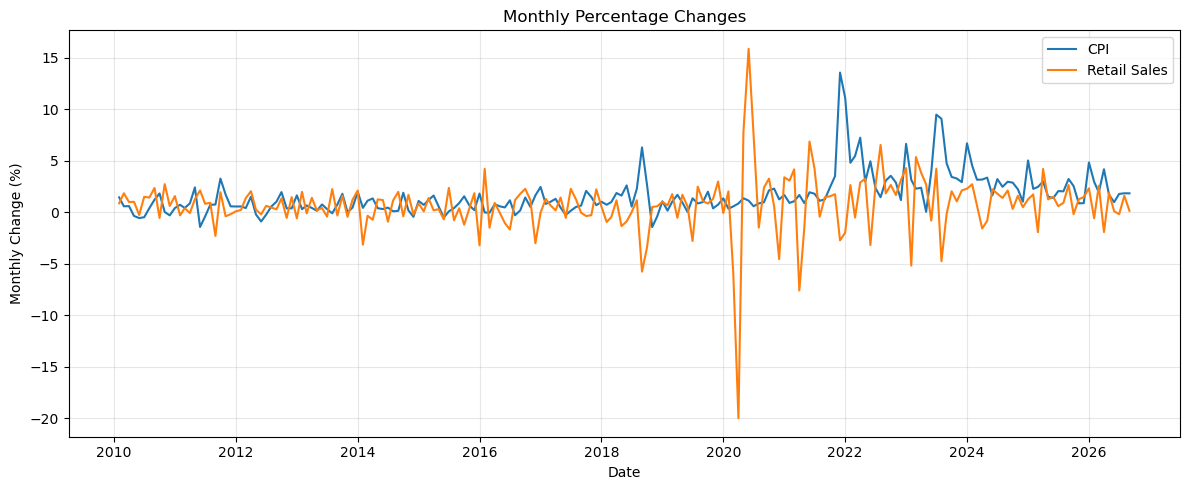

In [2]:
# Load cleaned dataset
df = pd.read_csv("turkey_cpi_retail_cleaned.csv")
df["date"] = pd.to_datetime(df["date"])

# Descriptive statistics
print("Descriptive Statistics:")
display(df[["cpi", "retail_sales"]].describe().round(2))

# Calculate monthly percentage changes
df["cpi_monthly_change"] = df["cpi"].pct_change() * 100
df["retail_monthly_change"] = df["retail_sales"].pct_change() * 100

print("\nMonthly Percentage Changes:")
display(
    df[["cpi_monthly_change", "retail_monthly_change"]]
    .describe()
    .round(2)
)

# Plot CPI trend
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["cpi"])
plt.title("Consumer Price Index in Türkiye (2010–2026)")
plt.xlabel("Date")
plt.ylabel("CPI Index")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cpi_trend.png", dpi=300)
plt.show()

# Plot Retail Sales trend
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["retail_sales"])
plt.title("Retail Sales Volume Index in Türkiye (2010–2026)")
plt.xlabel("Date")
plt.ylabel("Retail Sales Volume Index")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("retail_sales_trend.png", dpi=300)
plt.show()

# Plot monthly percentage changes
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["cpi_monthly_change"], label="CPI")
plt.plot(df["date"], df["retail_monthly_change"], label="Retail Sales")
plt.title("Monthly Percentage Changes")
plt.xlabel("Date")
plt.ylabel("Monthly Change (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("monthly_changes.png", dpi=300)
plt.show()

Correlation Matrix:


,cpi,retail_sales,cpi_monthly_change,retail_monthly_change
cpi,1.000,0.971,0.340,0.066
retail_sales,0.971,1.000,0.423,0.107
cpi_monthly_change,0.340,0.423,1.000,-0.061
retail_monthly_change,0.066,0.107,-0.061,1.000


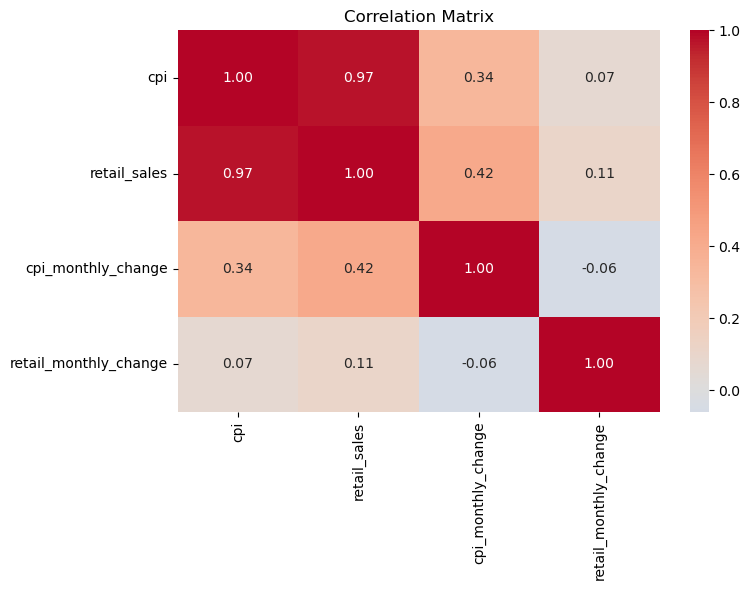

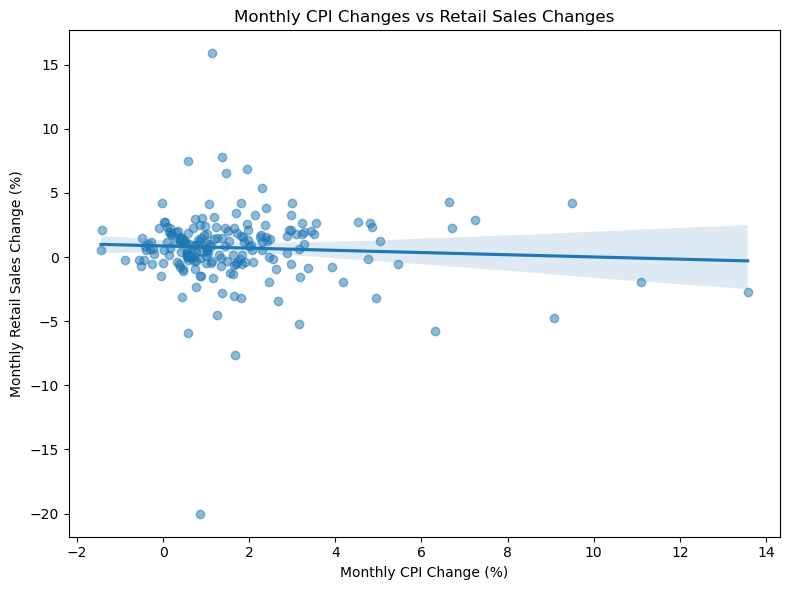

In [3]:
df = pd.read_csv("turkey_cpi_retail_cleaned.csv")

df["cpi_monthly_change"] = df["cpi"].pct_change() * 100
df["retail_monthly_change"] = df["retail_sales"].pct_change() * 100

# Correlation matrix
correlation = df[
    ["cpi", "retail_sales",
     "cpi_monthly_change", "retail_monthly_change"]
].corr()

print("Correlation Matrix:")
display(correlation.round(3))

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=300)
plt.show()

# Scatter plot of monthly changes
plt.figure(figsize=(8, 6))
sns.regplot(
    data=df,
    x="cpi_monthly_change",
    y="retail_monthly_change",
    scatter_kws={"alpha": 0.5}
)

plt.title("Monthly CPI Changes vs Retail Sales Changes")
plt.xlabel("Monthly CPI Change (%)")
plt.ylabel("Monthly Retail Sales Change (%)")
plt.tight_layout()
plt.savefig("monthly_correlation.png", dpi=300)
plt.show()

In [4]:
from statsmodels.tsa.stattools import adfuller

df = pd.read_csv("turkey_cpi_retail_cleaned.csv")

variables = ["cpi", "retail_sales"]

for column in variables:
    result = adfuller(df[column].dropna())

    print(f"\nADF Test: {column}")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print(f"Critical Value (1%): {result[4]['1%']:.4f}")
    print(f"Critical Value (5%): {result[4]['5%']:.4f}")
    print(f"Critical Value (10%): {result[4]['10%']:.4f}")

    if result[1] < 0.05:
        print("Result: Stationary")
    else:
        print("Result: Non-Stationary")


ADF Test: cpi
ADF Statistic: 0.5806
p-value: 0.9871
Critical Value (1%): -3.4660
Critical Value (5%): -2.8772
Critical Value (10%): -2.5751
Result: Non-Stationary

ADF Test: retail_sales
ADF Statistic: 3.7344
p-value: 1.0000
Critical Value (1%): -3.4640
Critical Value (5%): -2.8763
Critical Value (10%): -2.5747
Result: Non-Stationary


In [5]:
df["cpi_diff"] = df["cpi"].diff()
df["retail_sales_diff"] = df["retail_sales"].diff()

variables = ["cpi_diff", "retail_sales_diff"]

for column in variables:
    result = adfuller(df[column].dropna())

    print(f"\nADF Test: {column}")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print(f"Critical Value (5%): {result[4]['5%']:.4f}")

    if result[1] < 0.05:
        print("Result: Stationary")
    else:
        print("Result: Non-Stationary")


ADF Test: cpi_diff
ADF Statistic: 0.3722
p-value: 0.9804
Critical Value (5%): -2.8774
Result: Non-Stationary

ADF Test: retail_sales_diff
ADF Statistic: -3.0103
p-value: 0.0339
Critical Value (5%): -2.8768
Result: Stationary


In [6]:
df["cpi_diff2"] = df["cpi_diff"].diff()

result = adfuller(df["cpi_diff2"].dropna())

print("ADF Test: cpi_diff2")
print(f"ADF Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4f}")
print(f"Critical Value (5%): {result[4]['5%']:.4f}")

if result[1] < 0.05:
    print("Result: Stationary")
else:
    print("Result: Non-Stationary")

ADF Test: cpi_diff2
ADF Statistic: -5.0560
p-value: 0.0000
Critical Value (5%): -2.8775
Result: Stationary


In [7]:
df["inflation_monthly"] = df["cpi"].pct_change() * 100
df["retail_growth_monthly"] = df["retail_sales"].pct_change() * 100

print(df[[
    "inflation_monthly",
    "retail_growth_monthly"
]].describe())

       inflation_monthly  retail_growth_monthly
count         200.000000             200.000000
mean            1.642917               0.725366
std             1.976989               2.791821
min            -1.442921             -20.013857
25%             0.505467              -0.301746
50%             1.122580               0.913583
75%             2.251347               1.859381
max            13.575490              15.884153


In [8]:
variables = ["inflation_monthly", "retail_growth_monthly"]

for column in variables:
    result = adfuller(df[column].dropna())

    print(f"\nADF Test: {column}")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print(f"Critical Value (5%): {result[4]['5%']:.4f}")

    if result[1] < 0.05:
        print("Result: Stationary")
    else:
        print("Result: Non-Stationary")


ADF Test: inflation_monthly
ADF Statistic: -1.9187
p-value: 0.3233
Critical Value (5%): -2.8770
Result: Non-Stationary

ADF Test: retail_growth_monthly
ADF Statistic: -12.9882
p-value: 0.0000
Critical Value (5%): -2.8763
Result: Stationary


In [9]:
df["inflation_diff"] = df["inflation_monthly"].diff()

result = adfuller(df["inflation_diff"].dropna())

print("ADF Test: inflation_diff")
print(f"ADF Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4f}")
print(f"Critical Value (5%): {result[4]['5%']:.4f}")

if result[1] < 0.05:
    print("Result: Stationary")
else:
    print("Result: Non-Stationary")

ADF Test: inflation_diff
ADF Statistic: -6.8923
p-value: 0.0000
Critical Value (5%): -2.8770
Result: Stationary


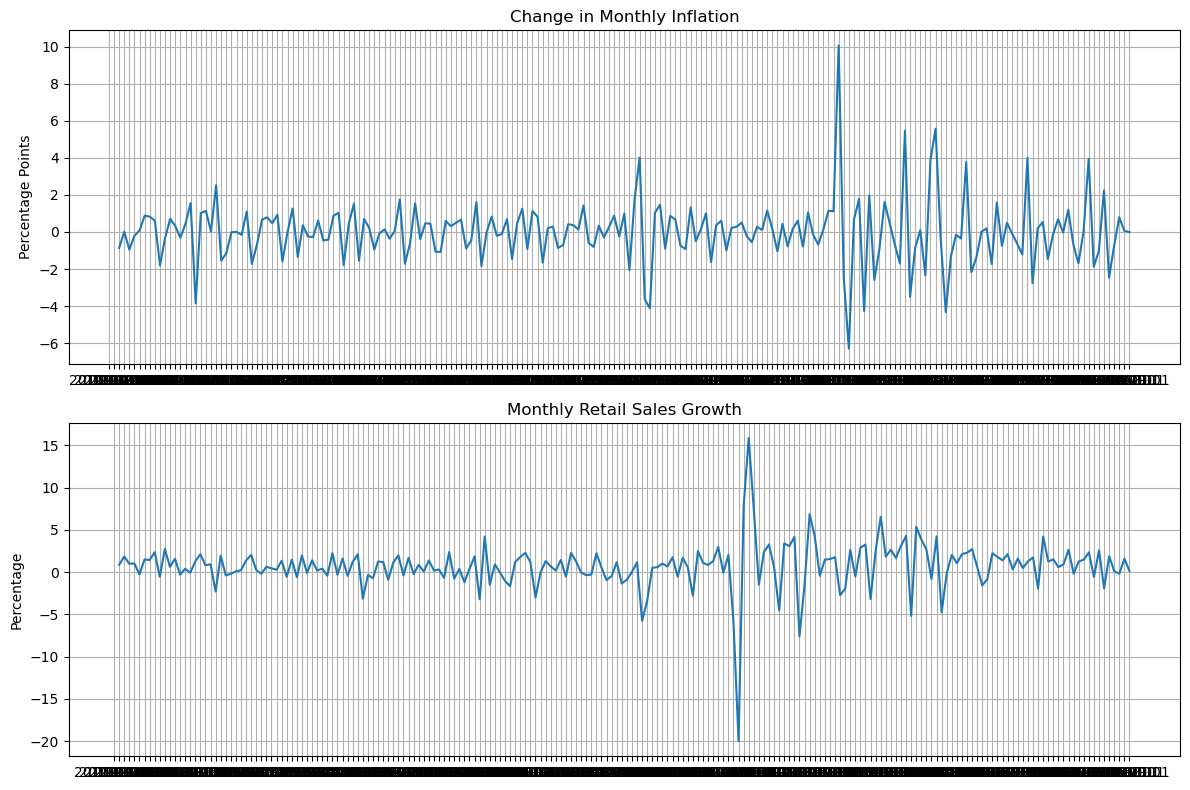

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(df["date"], df["inflation_diff"])
axes[0].set_title("Change in Monthly Inflation")
axes[0].set_ylabel("Percentage Points")
axes[0].grid(True)

axes[1].plot(df["date"], df["retail_growth_monthly"])
axes[1].set_title("Monthly Retail Sales Growth")
axes[1].set_ylabel("Percentage")
axes[1].grid(True)

plt.tight_layout()
plt.savefig("stationary_variables.png", dpi=300)
plt.show()

In [11]:
import statsmodels.api as sm

regression_data = df[
    ["inflation_diff", "retail_growth_monthly"]
].dropna()

X = regression_data["inflation_diff"]
y = regression_data["retail_growth_monthly"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit(cov_type="HC3")

print(model.summary())

                              OLS Regression Results                             
Dep. Variable:     retail_growth_monthly   R-squared:                       0.002
Model:                               OLS   Adj. R-squared:                 -0.003
Method:                    Least Squares   F-statistic:                    0.4279
Date:                   Wed, 25 Nov 2026   Prob (F-statistic):              0.514
Time:                           03:01:07   Log-Likelihood:                -486.45
No. Observations:                    199   AIC:                             976.9
Df Residuals:                        197   BIC:                             983.5
Df Model:                              1                                         
Covariance Type:                     HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const         

In [12]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

bg_test = acorr_breusch_godfrey(model, nlags=12)

print("Breusch-Godfrey Test")
print(f"LM Statistic: {bg_test[0]:.4f}")
print(f"LM p-value: {bg_test[1]:.4f}")
print(f"F Statistic: {bg_test[2]:.4f}")
print(f"F p-value: {bg_test[3]:.4f}")

Breusch-Godfrey Test
LM Statistic: 29.5019
LM p-value: 0.0033
F Statistic: 2.6833
F p-value: 0.0024


In [13]:
df["retail_growth_lag1"] = df["retail_growth_monthly"].shift(1)
df["inflation_diff_lag1"] = df["inflation_diff"].shift(1)

regression_data = df[
    [
        "retail_growth_monthly",
        "inflation_diff",
        "inflation_diff_lag1",
        "retail_growth_lag1"
    ]
].dropna()

y = regression_data["retail_growth_monthly"]

X = regression_data[
    [
        "inflation_diff",
        "inflation_diff_lag1",
        "retail_growth_lag1"
    ]
]

X = sm.add_constant(X)

model_dynamic = sm.OLS(y, X).fit(cov_type="HC3")

print(model_dynamic.summary())

                              OLS Regression Results                             
Dep. Variable:     retail_growth_monthly   R-squared:                       0.019
Model:                               OLS   Adj. R-squared:                  0.004
Method:                    Least Squares   F-statistic:                    0.8715
Date:                   Wed, 25 Nov 2026   Prob (F-statistic):              0.457
Time:                           03:01:07   Log-Likelihood:                -482.76
No. Observations:                    198   AIC:                             973.5
Df Residuals:                        194   BIC:                             986.7
Df Model:                              3                                         
Covariance Type:                     HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
cons

In [14]:
bg_test_dynamic = acorr_breusch_godfrey(
    model_dynamic,
    nlags=12
)

print("Breusch-Godfrey Test - Dynamic Model")
print(f"LM Statistic: {bg_test_dynamic[0]:.4f}")
print(f"LM p-value: {bg_test_dynamic[1]:.4f}")
print(f"F Statistic: {bg_test_dynamic[2]:.4f}")
print(f"F p-value: {bg_test_dynamic[3]:.4f}")

Breusch-Godfrey Test - Dynamic Model
LM Statistic: 28.8249
LM p-value: 0.0042
F Statistic: 2.5842
F p-value: 0.0034


In [15]:
model_dynamic_hac = model_dynamic.get_robustcov_results(
    cov_type="HAC",
    maxlags=12
)

print(model_dynamic_hac.summary())

                              OLS Regression Results                             
Dep. Variable:     retail_growth_monthly   R-squared:                       0.019
Model:                               OLS   Adj. R-squared:                  0.004
Method:                    Least Squares   F-statistic:                     2.949
Date:                   Wed, 25 Nov 2026   Prob (F-statistic):             0.0339
Time:                           03:02:47   Log-Likelihood:                -482.76
No. Observations:                    198   AIC:                             973.5
Df Residuals:                        194   BIC:                             986.7
Df Model:                              3                                         
Covariance Type:                     HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
cons

In [18]:
joint_test = model_dynamic_hac.wald_test(
    "inflation_diff = 0, inflation_diff_lag1 = 0",
    scalar=True
)

print(joint_test)

<Wald test (chi2): statistic=8.568303439475315, p-value=0.013785310369580733, df_denom=2>


In [19]:
influence = model_dynamic.get_influence()

cooks_d = influence.cooks_distance[0]

diagnostics = pd.DataFrame({
    "date": df.loc[regression_data.index, "date"].values,
    "cooks_distance": cooks_d
})

threshold = 4 / len(regression_data)

print(f"Cook's Distance Threshold: {threshold:.4f}")
print("\nTop 10 Influential Observations:")
print(diagnostics.nlargest(10, "cooks_distance"))

print(
    "\nNumber of influential observations:",
    (cooks_d > threshold).sum()
)

Cook's Distance Threshold: 0.0202

Top 10 Influential Observations:
           date  cooks_distance
121  2020-05-01        1.321147
120  2020-04-01        0.480695
122  2020-06-01        0.292108
123  2020-07-01        0.226065
159  2023-07-01        0.106401
154  2023-02-01        0.095098
160  2023-08-01        0.057045
101  2018-09-01        0.050154
140  2021-12-01        0.042301
155  2023-03-01        0.034803

Number of influential observations: 14


In [20]:
influential_mask = cooks_d <= threshold

sensitivity_data = regression_data.loc[influential_mask].copy()

y_sensitivity = sensitivity_data["retail_growth_monthly"]

X_sensitivity = sensitivity_data[
    [
        "inflation_diff",
        "inflation_diff_lag1",
        "retail_growth_lag1"
    ]
]

X_sensitivity = sm.add_constant(X_sensitivity)

model_sensitivity = sm.OLS(
    y_sensitivity,
    X_sensitivity
).fit(cov_type="HAC", cov_kwds={"maxlags": 12})

print(model_sensitivity.summary())

joint_test_sensitivity = model_sensitivity.wald_test(
    "inflation_diff = 0, inflation_diff_lag1 = 0",
    scalar=True
)

print("\nJoint Wald Test:")
print(joint_test_sensitivity)

                              OLS Regression Results                             
Dep. Variable:     retail_growth_monthly   R-squared:                       0.008
Model:                               OLS   Adj. R-squared:                 -0.009
Method:                    Least Squares   F-statistic:                    0.6758
Date:                   Wed, 25 Nov 2026   Prob (F-statistic):              0.568
Time:                           03:06:04   Log-Likelihood:                -356.94
No. Observations:                    184   AIC:                             721.9
Df Residuals:                        180   BIC:                             734.7
Df Model:                              3                                         
Covariance Type:                     HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
cons

In [21]:
df["covid_period"] = (
    df["date"] >= "2020-03-01"
).astype(int)

df["covid_interaction"] = (
    df["inflation_diff"] * df["covid_period"]
)

df["inflation_lag_interaction"] = (
    df["inflation_diff_lag1"] * df["covid_period"]
)

regression_data_covid = df[
    [
        "retail_growth_monthly",
        "inflation_diff",
        "inflation_diff_lag1",
        "retail_growth_lag1",
        "covid_period",
        "covid_interaction",
        "inflation_lag_interaction"
    ]
].dropna()

y_covid = regression_data_covid["retail_growth_monthly"]

X_covid = regression_data_covid.drop(
    columns=["retail_growth_monthly"]
)

X_covid = sm.add_constant(X_covid)

model_covid = sm.OLS(y_covid, X_covid).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

print(model_covid.summary())

                              OLS Regression Results                             
Dep. Variable:     retail_growth_monthly   R-squared:                       0.034
Model:                               OLS   Adj. R-squared:                  0.004
Method:                    Least Squares   F-statistic:                     2.345
Date:                   Wed, 25 Nov 2026   Prob (F-statistic):             0.0330
Time:                           03:06:38   Log-Likelihood:                -481.23
No. Observations:                    198   AIC:                             976.5
Df Residuals:                        191   BIC:                             999.5
Df Model:                              6                                         
Covariance Type:                     HAC                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------

In [22]:
interaction_test = model_covid.wald_test(
    "covid_interaction = 0, inflation_lag_interaction = 0",
    scalar=True
)

print("Joint Interaction Wald Test:")
print(interaction_test)

Joint Interaction Wald Test:
<Wald test (chi2): statistic=0.653371041529058, p-value=0.7213105445511404, df_denom=2>


In [23]:
from statsmodels.stats.diagnostic import breaks_cusumolsresid

pre_covid = regression_data_covid[
    df.loc[regression_data_covid.index, "date"] < "2020-03-01"
]

post_covid = regression_data_covid[
    df.loc[regression_data_covid.index, "date"] >= "2020-03-01"
]

y_pre = pre_covid["retail_growth_monthly"]
X_pre = sm.add_constant(
    pre_covid.drop(columns=["retail_growth_monthly",
                            "covid_period",
                            "covid_interaction",
                            "inflation_lag_interaction"])
)

y_post = post_covid["retail_growth_monthly"]
X_post = sm.add_constant(
    post_covid.drop(columns=["retail_growth_monthly",
                             "covid_period",
                             "covid_interaction",
                             "inflation_lag_interaction"])
)

model_pre = sm.OLS(y_pre, X_pre).fit()
model_post = sm.OLS(y_post, X_post).fit()

print("Pre-COVID observations:", len(y_pre))
print("Post-COVID observations:", len(y_post))
print("Pre-COVID RSS:", model_pre.ssr)
print("Post-COVID RSS:", model_post.ssr)

Pre-COVID observations: 119
Post-COVID observations: 79
Pre-COVID RSS: 233.8021197588156
Post-COVID RSS: 1253.704525178207


In [24]:
from scipy.stats import f

rss_pooled = model_covid.ssr
rss_pre = model_pre.ssr
rss_post = model_post.ssr

n_pre = len(y_pre)
n_post = len(y_post)

k = X_pre.shape[1]

chow_stat = (
    (rss_pooled - (rss_pre + rss_post)) / k
) / (
    (rss_pre + rss_post) / (n_pre + n_post - 2 * k)
)

chow_pvalue = 1 - f.cdf(
    chow_stat,
    k,
    n_pre + n_post - 2 * k
)

print("Chow F-statistic:", chow_stat)
print("P-value:", chow_pvalue)

Chow F-statistic: 0.3076174520895201
P-value: 0.8726464751672962
